# ML Assignment 1 - Predict Uber ride price (Linear Regression vs Random Forest)

**Problem statement:** predict the fare of an Uber ride from pickup/drop-off location, time and passenger count. Pre-process the dataset, identify outliers, check the correlation, implement Linear Regression and Random Forest Regression, and compare R2 and RMSE.

**Libraries used:** pandas, numpy (data handling), seaborn/matplotlib (plots), scikit-learn (models, metrics).

**Driver:** the Kaggle *Uber Fares* CSV is not available offline, so a seeded synthetic dataset with the same columns is generated. To use the real file set `CSV_PATH = "uber.csv"` in the first code cell. No input is taken at runtime.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

CSV_PATH = None  # e.g. "uber.csv" for the real Kaggle dataset


def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km (Euclidean distance is wrong on a sphere)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

## 1. Load the dataset (synthetic stand-in with the Kaggle columns)

In [2]:
def make_data(n=4000, seed=42):
    rng = np.random.default_rng(seed)
    df = pd.DataFrame({
        "pickup_datetime": pd.to_datetime("2009-01-01") + pd.to_timedelta(rng.integers(0, 6 * 365 * 24 * 60, n), unit="m"),
        "pickup_longitude": -73.98 + rng.normal(0, 0.03, n),
        "pickup_latitude": 40.75 + rng.normal(0, 0.03, n),
        "dropoff_longitude": -73.98 + rng.normal(0, 0.04, n),
        "dropoff_latitude": 40.75 + rng.normal(0, 0.04, n),
        "passenger_count": rng.integers(1, 6, n),
    })
    dist = haversine_km(df.pickup_latitude, df.pickup_longitude, df.dropoff_latitude, df.dropoff_longitude)
    rush = df.pickup_datetime.dt.hour.isin([8, 9, 17, 18, 19]) * 1.5
    df["fare_amount"] = (2.5 + 1.8 * dist + rush + rng.normal(0, 1.0, n)).round(2)
    # dirty rows, as in the real dataset: negative/huge fares, impossible coordinates, a missing value
    df.loc[0:4, "fare_amount"] = [-5.0, -2.5, 450.0, 499.0, 300.0]
    df.loc[5:7, "pickup_latitude"] = [0.0, 91.5, 0.0]
    df.loc[8, "dropoff_longitude"] = np.nan
    return df


df = pd.read_csv(CSV_PATH) if CSV_PATH else make_data()
print(f"Dataset: {df.shape[0]} rows x {df.shape[1]} columns")
print(df.head().to_string())
print("\nMissing values:", df.isnull().sum()[df.isnull().sum() > 0].to_dict())

Dataset: 4000 rows x 7 columns
      pickup_datetime  pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  passenger_count  fare_amount
0 2009-07-15 11:01:00        -73.952758        40.722649         -73.954544         40.740395                5         -5.0
1 2013-08-22 23:07:00        -74.016081        40.773416         -73.881541         40.715536                2         -2.5
2 2012-12-04 12:16:00        -73.988591        40.706549         -74.011293         40.731431                4        450.0
3 2011-08-20 03:27:00        -73.997582        40.787249         -74.050538         40.742888                4        499.0
4 2011-08-07 07:16:00        -73.975070        40.737722         -73.979711         40.782164                5        300.0

Missing values: {'dropoff_longitude': 1}


## 2. Pre-process: drop unused columns and nulls, split the date/time, compute distance

In [3]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore").dropna()
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce")
df = df.assign(hour=df.pickup_datetime.dt.hour, day=df.pickup_datetime.dt.day, month=df.pickup_datetime.dt.month,
               year=df.pickup_datetime.dt.year, dayofweek=df.pickup_datetime.dt.dayofweek).drop(columns="pickup_datetime")
df["dist_km"] = haversine_km(df.pickup_latitude, df.pickup_longitude, df.dropoff_latitude, df.dropoff_longitude)
print(df.describe().loc[["min", "mean", "max"], ["fare_amount", "dist_km", "passenger_count"]].round(2).to_string())

      fare_amount  dist_km  passenger_count
min         -5.00     0.15              1.0
mean        14.39     9.93              3.0
max        499.00  5635.02              5.0


## 3. Identify and handle outliers
Impossible rows (negative fare, invalid coordinates, zero or >130 km trips) are removed; the rest are clipped to the IQR whiskers.

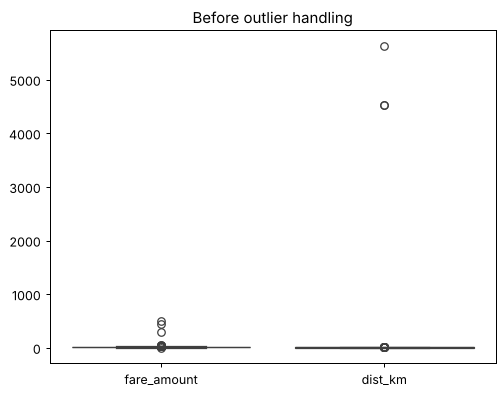

In [4]:
sns.boxplot(data=df[["fare_amount", "dist_km"]])
plt.title("Before outlier handling")

In [5]:
valid = ((df.fare_amount > 0) & df.pickup_latitude.between(-90, 90) & df.dropoff_latitude.between(-90, 90)
         & df.pickup_longitude.between(-180, 180) & df.dropoff_longitude.between(-180, 180)
         & (df.dist_km > 0) & (df.dist_km <= 130) & df.passenger_count.between(1, 6))
print("Invalid rows removed:", (~valid).sum())
df = df[valid].copy()
for col in ("fare_amount", "dist_km"):
    q1, q3 = df[col].quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    print(f"{col}: {((df[col] < low) | (df[col] > high)).sum()} IQR outliers clipped to [{low:.2f}, {high:.2f}]")
    df[col] = df[col].clip(low, high)

Invalid rows removed: 5
fare_amount: 52 IQR outliers clipped to [-2.74, 30.13]
dist_km: 51 IQR outliers clipped to [-2.96, 15.00]


## 4. Check the correlation

dist_km              0.977
dropoff_latitude     0.024
dropoff_longitude    0.024
pickup_longitude     0.023
passenger_count      0.017
dayofweek            0.007
hour                 0.006
year                -0.014
day                 -0.015
pickup_latitude     -0.016
month               -0.019


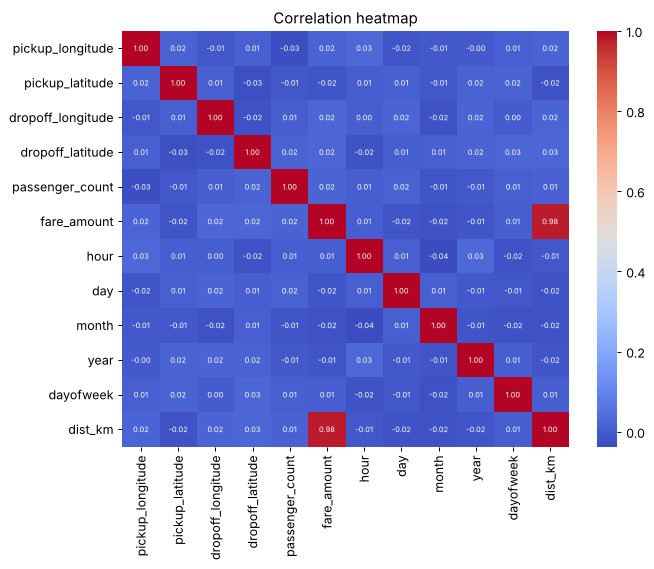

In [6]:
corr = df.corr()
print(corr["fare_amount"].drop("fare_amount").sort_values(ascending=False).round(3).to_string())
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 6})
plt.title("Correlation heatmap")

## 5. Train Linear Regression and Random Forest, then compare

In [7]:
features = ["pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
            "passenger_count", "hour", "day", "month", "year", "dayofweek", "dist_km"]
X_train, X_test, y_train, y_test = train_test_split(df[features], df["fare_amount"], test_size=0.33, random_state=1)

models = {"Linear Regression": LinearRegression(), "Random Forest": RandomForestRegressor(n_estimators=100, random_state=1)}
results = {}
print(f"{'model':<20}{'R2':>8}{'RMSE':>8}")
for name, model in models.items():
    pred = model.fit(X_train, y_train).predict(X_test)
    results[name] = (r2_score(y_test, pred), np.sqrt(mean_squared_error(y_test, pred)))
    print(f"{name:<20}{results[name][0]:>8.3f}{results[name][1]:>8.3f}")

model                     R2    RMSE
Linear Regression      0.961   1.155
Random Forest          0.959   1.187


**Conclusion:** distance is by far the strongest predictor of fare. Compare the R2 (higher is better) and RMSE (lower is better) above to choose the better model.